In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [4]:
df = pd.read_csv("StudentPerformanceFactors.csv")
df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


## Feature Engineering

In [5]:
## Removing irrelevant columns

df.drop(['Family_Income','Learning_Disabilities','Parental_Education_Level','Distance_from_Home','Internet_Access','Teacher_Quality','School_Type','Gender','Physical_Activity'],axis=1,inplace=True)


In [6]:
df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Tutoring_Sessions,Peer_Influence,Exam_Score
0,23,84,Low,High,No,7,73,Low,0,Positive,67
1,19,64,Low,Medium,No,8,59,Low,2,Negative,61
2,24,98,Medium,Medium,Yes,7,91,Medium,2,Neutral,74
3,29,89,Low,Medium,Yes,8,98,Medium,1,Negative,71
4,19,92,Medium,Medium,Yes,6,65,Medium,3,Neutral,70


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Hours_Studied               6607 non-null   int64
 1   Attendance                  6607 non-null   int64
 2   Parental_Involvement        6607 non-null   str  
 3   Access_to_Resources         6607 non-null   str  
 4   Extracurricular_Activities  6607 non-null   str  
 5   Sleep_Hours                 6607 non-null   int64
 6   Previous_Scores             6607 non-null   int64
 7   Motivation_Level            6607 non-null   str  
 8   Tutoring_Sessions           6607 non-null   int64
 9   Peer_Influence              6607 non-null   str  
 10  Exam_Score                  6607 non-null   int64
dtypes: int64(6), str(5)
memory usage: 567.9 KB


In [8]:
df.describe()

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,101.000000


In [9]:
df[df['Exam_Score'] == 101]

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Tutoring_Sessions,Peer_Influence,Exam_Score
1525,27,98,Low,Medium,Yes,6,93,Low,5,Positive,101


In [10]:
#Remove invalid row
df = df[df['Exam_Score']<=100]


In [11]:
df.describe()

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Exam_Score
count,6606.000000,6606.000000,6606.000000,6606.000000,6606.000000,6606.000000
mean,19.974266,79.974720,7.029216,75.067817,1.493188,67.230548
std,5.990424,11.546219,1.468177,14.399184,1.229907,3.868502
min,1.000000,60.000000,4.000000,50.000000,0.000000,55.000000
25%,16.000000,70.000000,6.000000,63.000000,1.000000,65.000000
50%,20.000000,80.000000,7.000000,75.000000,1.000000,67.000000
75%,24.000000,90.000000,8.000000,88.000000,2.000000,69.000000
max,44.000000,100.000000,10.000000,100.000000,8.000000,100.000000


In [12]:
df.columns

Index(['Hours_Studied', 'Attendance', 'Parental_Involvement',
       'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours',
       'Previous_Scores', 'Motivation_Level', 'Tutoring_Sessions',
       'Peer_Influence', 'Exam_Score'],
      dtype='str')

In [13]:
df['Parental_Involvement'].unique()

<StringArray>
['Low', 'Medium', 'High']
Length: 3, dtype: str

In [14]:
df['Parental_Involvement'] = df['Parental_Involvement'].map({'Low':0,'Medium':1,'High':2}).astype(int)

In [15]:
df['Parental_Involvement'].unique()

array([0, 1, 2])

In [16]:
df['Motivation_Level'].unique()

<StringArray>
['Low', 'Medium', 'High']
Length: 3, dtype: str

In [17]:
df['Motivation_Level'] = df['Motivation_Level'].map({'Low':0,'Medium':1,'High':2}).astype(int)

In [18]:
df['Access_to_Resources'] = df['Access_to_Resources'].map({'Low':0,'Medium':1,'High':2}).astype(int)

In [19]:
df['Extracurricular_Activities'] = df['Extracurricular_Activities'].map({'Yes':1,'No':0}).astype(int)

In [20]:
df['Peer_Influence'].unique()

<StringArray>
['Positive', 'Negative', 'Neutral']
Length: 3, dtype: str

In [21]:
df['Peer_Influence'] = df['Peer_Influence'].map({'Negative':0,'Neutral':1,'Positive':2}).astype(int)

In [22]:
#Converting score to cgpa

In [23]:
df['Exam_Score'] = (df['Exam_Score']/10).astype(float)

In [24]:
df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Tutoring_Sessions,Peer_Influence,Exam_Score
0,23,84,0,2,0,7,73,0,0,2,6.7
1,19,64,0,1,0,8,59,0,2,0,6.1
2,24,98,1,1,1,7,91,1,2,1,7.4
3,29,89,0,1,1,8,98,1,1,0,7.1
4,19,92,1,1,1,6,65,1,3,1,7.0


In [25]:
df.info()

<class 'pandas.DataFrame'>
Index: 6606 entries, 0 to 6606
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Hours_Studied               6606 non-null   int64  
 1   Attendance                  6606 non-null   int64  
 2   Parental_Involvement        6606 non-null   int64  
 3   Access_to_Resources         6606 non-null   int64  
 4   Extracurricular_Activities  6606 non-null   int64  
 5   Sleep_Hours                 6606 non-null   int64  
 6   Previous_Scores             6606 non-null   int64  
 7   Motivation_Level            6606 non-null   int64  
 8   Tutoring_Sessions           6606 non-null   int64  
 9   Peer_Influence              6606 non-null   int64  
 10  Exam_Score                  6606 non-null   float64
dtypes: float64(1), int64(10)
memory usage: 619.3 KB


In [26]:
df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Tutoring_Sessions,Peer_Influence,Exam_Score
0,23,84,0,2,0,7,73,0,0,2,6.7
1,19,64,0,1,0,8,59,0,2,0,6.1
2,24,98,1,1,1,7,91,1,2,1,7.4
3,29,89,0,1,1,8,98,1,1,0,7.1
4,19,92,1,1,1,6,65,1,3,1,7.0


# Exploratory Data Analysis

In [27]:
df.corr()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Tutoring_Sessions,Peer_Influence,Exam_Score
Hours_Studied,1.000000,-0.010188,-0.015819,-0.005427,-0.006164,0.011103,0.024630,-0.010167,-0.014799,0.009510,0.446514
Attendance,-0.010188,1.000000,-0.008947,-0.011477,-0.002417,-0.015756,-0.020487,-0.004704,0.013661,-0.007774,0.582458
Parental_Involvement,-0.015819,-0.008947,1.000000,-0.026596,-0.021692,-0.008113,-0.020786,-0.022709,-0.001434,0.021572,0.160112
Access_to_Resources,-0.005427,-0.011477,-0.026596,1.000000,-0.008187,-0.014520,0.023894,0.006179,-0.011720,-0.001224,0.170936
Extracurricular_Activities,-0.006164,-0.002417,-0.021692,-0.008187,1.000000,0.001466,0.004200,0.016280,0.002839,0.009010,0.063667
Sleep_Hours,0.011103,-0.015756,-0.008113,-0.014520,0.001466,1.000000,-0.021622,0.000893,-0.011922,-0.016755,-0.016194
Previous_Scores,0.024630,-0.020487,-0.020786,0.023894,0.004200,-0.021622,1.000000,0.006707,-0.013669,-0.018187,0.174461
Motivation_Level,-0.010167,-0.004704,-0.022709,0.006179,0.016280,0.000893,0.006707,1.000000,0.001822,-0.000091,0.089171
Tutoring_Sessions,-0.014799,0.013661,-0.001434,-0.011720,0.002839,-0.011922,-0.013669,0.001822,1.000000,-0.005605,0.153754
Peer_Influence,0.009510,-0.007774,0.021572,-0.001224,0.009010,-0.016755,-0.018187,-0.000091,-0.005605,1.000000,0.099387


In [28]:
df.corr(numeric_only=True)['Exam_Score'].sort_values(
    ascending=False
)

Exam_Score                    1.000000
Attendance                    0.582458
Hours_Studied                 0.446514
Previous_Scores               0.174461
Access_to_Resources           0.170936
Parental_Involvement          0.160112
Tutoring_Sessions             0.153754
Peer_Influence                0.099387
Motivation_Level              0.089171
Extracurricular_Activities    0.063667
Sleep_Hours                  -0.016194
Name: Exam_Score, dtype: float64

<Axes: >

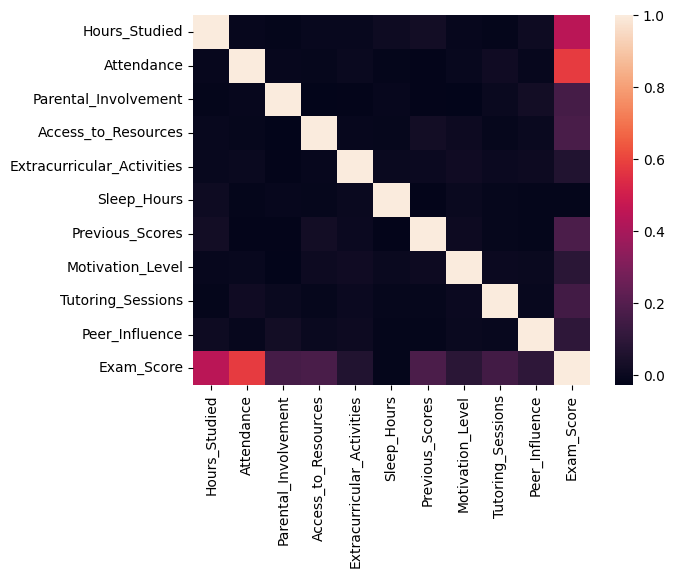

In [29]:
sns.heatmap(df.corr())

<Axes: >

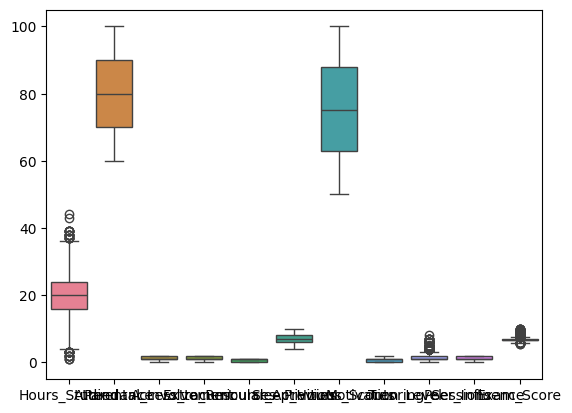

In [30]:
sns.boxplot(df)

In [31]:
df.to_csv('FinalSP.csv',index=False)